# Mejora 1: más épocas con *warmup* + *cosine annealing* del learning rate

**Faster R-CNN v2 (ResNet-50 + FPN) sobre *pills-sxdht*.** Primer experimento de mejora sobre el baseline (`baseline-faster-r-cnn-v2.ipynb`).

## Hipótesis

El análisis de errores del baseline (sección 13) concluye que **el margen principal está en la localización**: a IoU 0.85 el error `loc` cuesta +0.096 de AP en validación y +0.092 en test, mientras que a IoU 0.5 casi no queda margen (mAP@0.5 = 0.981 en test). El modelo encuentra y clasifica bien las pastillas, pero **no ajusta las cajas al píxel**.

Dos síntomas del entrenamiento del baseline apuntan al *learning rate*:

1. **El mAP de validación seguía subiendo en la última época** (0.881 en la época 15, la mejor): el entrenamiento se cortó antes de converger.
2. **Con LR constante el mAP de validación oscila** entre épocas (0.852 → 0.819 → 0.861, 0.878 → 0.860 → 0.881). Con un paso de 0.005 fijo, el optimizador sigue "rebotando" alrededor del mínimo y no puede hacer los ajustes pequeños que necesita la regresión de cajas para pasar de IoU 0.8 a 0.9.

Una política que **baje el LR progresivamente hasta casi cero** debería permitir ese ajuste fino al final del entrenamiento, y más épocas dan tiempo a que ocurra.

## Qué cambia respecto al baseline

| Aspecto | Baseline | Mejora 1 |
|---|---|---|
| Épocas | 15 | **30** |
| Política de LR | constante (0.005) | ***warmup* lineal 1 época + *cosine annealing* hasta 0**, actualizado por iteración |
| Todo lo demás | | **igual**: datos, limpieza, modelo, SGD (lr máx. 0.005, momentum 0.9, wd 5e-4), batch 4, semilla, evaluación |

- ***Warmup***: durante la primera época el LR sube linealmente desde 0.001·LR hasta LR. Evita que los gradientes grandes de la cabeza nueva (inicializada al azar) desajusten los pesos preentrenados de COCO en las primeras iteraciones. Es lo que hace el script de referencia de torchvision para detección.
- ***Cosine annealing***: después el LR baja siguiendo medio coseno, de 0.005 a 0. Pasa mucho tiempo con LR alto (exploración) y se frena suavemente al final (ajuste fino), sin los saltos bruscos de un `StepLR`.

Las dos cosas forman una única estrategia: **la política de entrenamiento** (cuánto se entrena y con qué paso). Si hay tiempo, se puede separar el efecto de cada parte repitiendo este cuaderno con `NUM_EPOCHS = 15` (mismo presupuesto que el baseline, solo cambia el *scheduler*).

## Cómo se comprueba

- **Métrica de decisión**: mAP@0.5:0.95 en **validación** (test solo se usa para informar).
- **Comprobación de la hipótesis**: si la mejora actúa sobre la localización, debería bajar el ΔAP de `loc` a IoU 0.85 en la descomposición TIDE (sección 7), y subir sobre todo el mAP@0.5:0.95 y no tanto el mAP@0.5.
- **Coste**: el modelo es el mismo, así que el tiempo de inferencia no debe cambiar; el de entrenamiento se duplica (~80 min en una T4).

## 1. Configuración

El código común con el baseline (dataset, limpieza de clases, DataLoaders, entrenamiento, evaluación y TIDE) está en `faster_rcnn/common.py`, junto a este cuaderno. Si no está (Kaggle, Colab), se descarga del repositorio del grupo, igual que `mapviz.py` (en la raíz del repositorio) y los resultados del baseline.

Todos los hiperparámetros están en esta celda. Los marcados con `# CAMBIO` son los únicos que difieren del baseline.

In [1]:
# Dependencias que pueden no estar instaladas
try:
    import datasets, torchmetrics, pycocotools  # noqa: F401
except ImportError:
    %pip install -q datasets torchmetrics pycocotools

import sys
import urllib.request
from pathlib import Path

if not Path("common.py").exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/HectorBarro/CV1_P6/main/faster_rcnn/common.py", "common.py")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np
import torch

import common as C

%matplotlib inline

In [2]:
EXP_NAME = "mejora01_cosine_fasterrcnn"
DESCRIPTION = "30 épocas con warmup lineal (1 época) + cosine annealing del LR, por iteración"

# ---------------- Hiperparámetros (iguales al baseline salvo los marcados) ----------------
SEED = 42
NUM_EPOCHS = 30          # CAMBIO: baseline 15
BATCH_SIZE = 4
LR = 0.005               # LR máximo (tras el warmup)
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
WARMUP_EPOCHS = 1        # CAMBIO: baseline sin warmup
WARMUP_FACTOR = 0.001    # el LR arranca en LR * WARMUP_FACTOR
MIN_LR_FACTOR = 0.0      # el coseno termina en LR * MIN_LR_FACTOR

OUT_DIR = C.RESULTS_ROOT / EXP_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)

C.set_seed(SEED)
print("Dispositivo:", C.describe_device())

Dispositivo: cuda (Tesla T4)


## 2. Datos y modelo

Exactamente igual que en el baseline (secciones 2 a 6): mismas particiones, misma limpieza de clases (7 clases + fondo, se eliminan las imágenes con `Ibuphil 600 mg`), sin aumento de datos, y Faster R-CNN v2 con pesos `COCO_V1` y un predictor nuevo.

Se mantiene también el **orden de las llamadas que usan la semilla** (modelo, DataLoaders, lote de ejemplo), para que la inicialización de la cabeza y el orden de las imágenes coincidan con los del baseline. Así la diferencia de resultados se debe a la política de LR y no al azar. En GPU puede quedar una pequeña variación porque algunas operaciones de torchvision no son deterministas.

In [3]:
hf, CLASSES = C.load_splits()
NUM_CLASSES = len(CLASSES)

model = C.build_model(NUM_CLASSES, seed=SEED)

ds = C.make_datasets(hf)
loaders = C.make_loaders(ds, BATCH_SIZE, SEED)
print(f"Imágenes -> train: {len(ds['train'])} | valid: {len(ds['valid'])} | test: {len(ds['test'])}")

# Igual que en el baseline: se saca un lote de ejemplo (esto también consume el generador de train)
images, targets = next(iter(loaders["train"]))
print("Ejemplo:", images[0].shape, "| cajas:", targets[0]["boxes"].shape[0], "| etiquetas:", targets[0]["labels"].tolist())

README.md:   0%|          | 0.00/3.51k [00:00<?, ?B/s]

data/train-00000-of-00001-d15b632ebb4ea5(…): reconstructing file:   0%|          |  0.00B / 17.1MB            

data/train-00000-of-00001-d15b632ebb4ea5(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-d6f6f66b7(…): reconstructing file:   0%|          |  0.00B / 2.64MB            

data/validation-00000-of-00001-d6f6f66b7(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-1afd43b66cacbc9(…): reconstructing file:   0%|          |  0.00B / 4.87MB            

... (6 outputs left out)

Filter:   0%|          | 0/316 [00:00<?, ? examples/s]

Filter:   0%|          | 0/45 [00:00<?, ? examples/s]

Filter:   0%|          | 0/90 [00:00<?, ? examples/s]

Imágenes -> train: 315 | valid: 45 | test: 89
Ejemplo: torch.Size([3, 640, 640]) | cajas: 1 | etiquetas: [6]


## 3. Optimizador y política de learning rate

El optimizador es el mismo SGD del baseline. El *scheduler* se actualiza **en cada iteración** (no en cada época), así que el coseno es una curva suave y el *warmup* ocupa las primeras `len(train_loader)` iteraciones.

La gráfica muestra el LR que se va a usar en cada iteración, frente al LR constante del baseline.

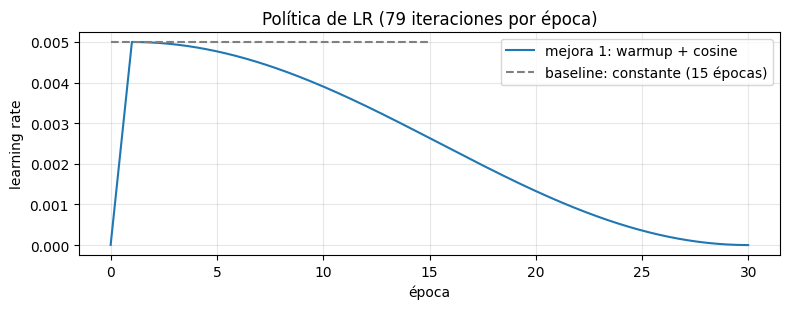

In [4]:
C.set_seed(SEED)
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

iters_per_epoch = len(loaders["train"])
total_iters = NUM_EPOCHS * iters_per_epoch
warmup_iters = WARMUP_EPOCHS * iters_per_epoch
scheduler = C.warmup_cosine_scheduler(optimizer, total_iters, warmup_iters,
                                      warmup_factor=WARMUP_FACTOR, min_factor=MIN_LR_FACTOR)

# Vista previa del LR (con un optimizador de prueba, para no tocar el real)
_opt = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=LR)
_sch = C.warmup_cosine_scheduler(_opt, total_iters, warmup_iters, WARMUP_FACTOR, MIN_LR_FACTOR)
lrs = []
for _ in range(total_iters):
    lrs.append(_opt.param_groups[0]["lr"])
    _opt.step()
    _sch.step()

epochs_axis = np.arange(total_iters) / iters_per_epoch
plt.figure(figsize=(8, 3.2))
plt.plot(epochs_axis, lrs, label="mejora 1: warmup + cosine")
plt.plot([0, 15], [LR, LR], "--", c="gray", label="baseline: constante (15 épocas)")
plt.xlabel("época")
plt.ylabel("learning rate")
plt.title(f"Política de LR ({iters_per_epoch} iteraciones por época)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "politica_lr.png", dpi=120)
plt.show()

## 4. Entrenamiento

Mismo bucle que el baseline: en cada época se registran las pérdidas de train y validación y el mAP de validación, y se guarda el modelo con **mayor mAP@0.5:0.95 en validación**. Test no se usa para ninguna decisión.

> ~160 s por época en una Tesla T4 → unos 80 min en total.

In [5]:
C.set_seed(SEED)
fit_result = C.fit(model, loaders, optimizer, NUM_EPOCHS, OUT_DIR, scheduler=scheduler)
history, best_epoch = fit_result["history"], fit_result["best_epoch"]

Época  1/30 | lr 0.00001 | loss train 0.5781 | loss val 0.2728 | val mAP 0.2980 | val mAP@50 0.6027 | 158s
Época  2/30 | lr 0.00500 | loss train 0.1907 | loss val 0.1038 | val mAP 0.6659 | val mAP@50 0.9024 | 157s
Época  3/30 | lr 0.00499 | loss train 0.0946 | loss val 0.0821 | val mAP 0.7157 | val mAP@50 0.9903 | 157s
Época  4/30 | lr 0.00494 | loss train 0.0716 | loss val 0.0616 | val mAP 0.7596 | val mAP@50 0.9950 | 157s
Época  5/30 | lr 0.00487 | loss train 0.0506 | loss val 0.0478 | val mAP 0.8075 | val mAP@50 0.9894 | 157s
Época  6/30 | lr 0.00477 | loss train 0.0465 | loss val 0.0516 | val mAP 0.8185 | val mAP@50 0.9890 | 157s
Época  7/30 | lr 0.00464 | loss train 0.0425 | loss val 0.0521 | val mAP 0.7665 | val mAP@50 0.9657 | 156s
Época  8/30 | lr 0.00449 | loss train 0.0379 | loss val 0.0457 | val mAP 0.8324 | val mAP@50 0.9657 | 157s
Época  9/30 | lr 0.00431 | loss train 0.0346 | loss val 0.0435 | val mAP 0.8109 | val mAP@50 0.9657 | 156s
Época 10/30 | lr 0.00412 | loss train

## 5. Curvas de entrenamiento frente al baseline

Los resultados del baseline se leen de `faster_rcnn/resultados/baseline_fasterrcnn/` (o se descargan del repositorio si no están en local).

Qué mirar:
- **mAP de validación**: con LR constante oscilaba; con el coseno debería estabilizarse y seguir subiendo cuando el LR se hace pequeño (últimas épocas).
- **Pérdida de validación**: si vuelve a subir mientras la de train baja, el entrenamiento largo estaría sobreajustando.

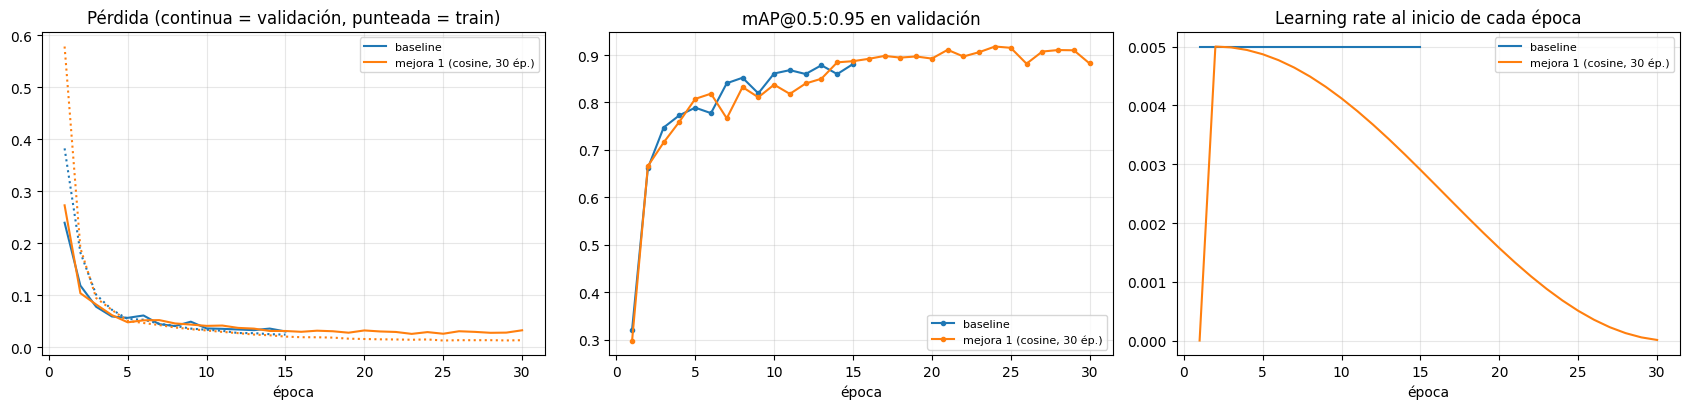

val mAP baseline : mejor 0.8809 (época 15) | desv. típica últimas 5 épocas 0.0089
val mAP mejora 1 : mejor 0.9179 (época 24) | desv. típica últimas 5 épocas 0.0134


In [6]:
baseline = C.load_experiment("baseline_fasterrcnn")
baseline["history"].setdefault("lr", [baseline["results"]["config"]["lr"]] * len(baseline["history"]["val_map"]))

C.plot_history_comparison({"baseline": baseline["history"], "mejora 1 (cosine, 30 ép.)": history},
                          out_path=OUT_DIR / "curvas_vs_baseline.png")

b_hist = baseline["history"]["val_map"]
print(f"val mAP baseline : mejor {max(b_hist):.4f} (época {int(np.argmax(b_hist)) + 1}) | "
      f"desv. típica últimas 5 épocas {np.std(b_hist[-5:]):.4f}")
print(f"val mAP mejora 1 : mejor {max(history['val_map']):.4f} (época {best_epoch}) | "
      f"desv. típica últimas 5 épocas {np.std(history['val_map'][-5:]):.4f}")

## 6. Evaluación en test

Con el mejor modelo de validación, igual que en la sección 10 del baseline: mAP de COCO, AP por clase, curvas PR y tiempo de inferencia (batch 1, mismo hardware).

mAP@0.5:0.95 : 0.8669
mAP@0.5      : 0.9848
mAP@0.75     : 0.9848
mAP pequeño / mediano / grande : 0.3000 / 0.8849 / 0.8229
mAR@100      : 0.8885

clase                   AP50:95     AP50
Cipro 500                0.8281   0.9192
Ibuphil Cold 400-60      0.8947   1.0000
Xyzall 5mg               0.8289   0.9835
blue                     0.9241   1.0000
pink                     0.9160   1.0000
red                      0.8520   1.0000
white                    0.8243   0.9910


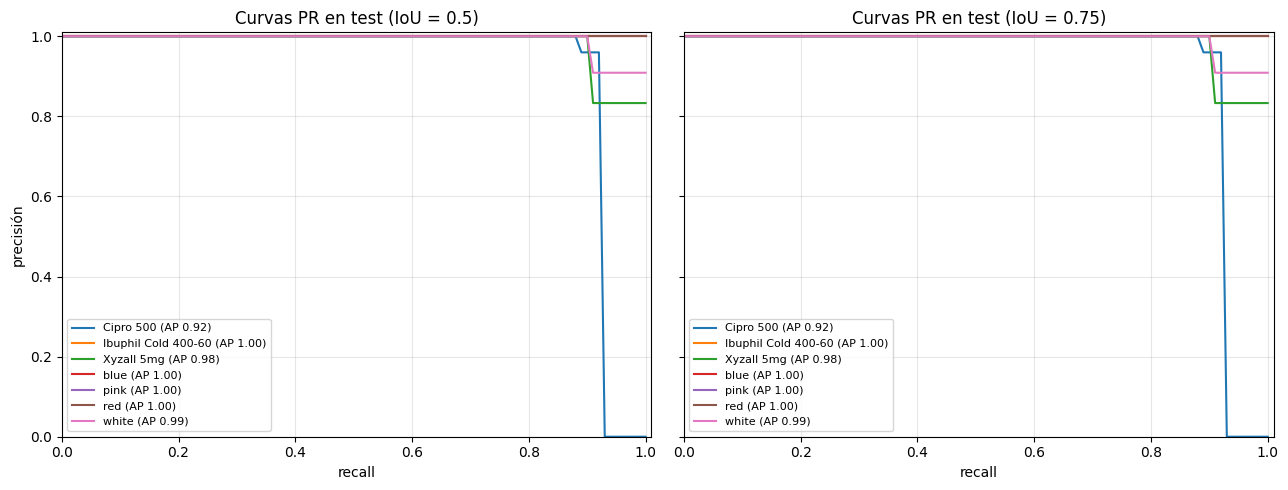


Hardware: Tesla T4 | inferencia: 173.9 ± 2.3 ms/imagen -> 5.8 FPS


In [7]:
res, per_class = C.test_report(model, loaders["test"], CLASSES)
C.plot_pr_curves(res, CLASSES, out_path=OUT_DIR / "curvas_pr_test.png")

times_ms = C.measure_inference(model, ds["test"])
print(f"\nHardware: {C.hardware_name()} | inferencia: {times_ms.mean():.1f} ± {times_ms.std():.1f} ms/imagen "
      f"-> {1000 / times_ms.mean():.1f} FPS")

### 6.1 Comparación con el baseline

Entre paréntesis, la diferencia con el baseline. La decisión de quedarse o no con la mejora se toma con la primera fila (**val mAP@0.5:0.95**); las filas de test son la estimación independiente del rendimiento.

Con 45 imágenes de validación y 89 de test, diferencias de **menos de 1 punto** de mAP pueden deberse al azar del entrenamiento: hay que interpretarlas con cautela.

In [8]:
config = {"seed": SEED, "epochs": NUM_EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
          "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY, "optimizer": "SGD",
          "scheduler": f"warmup lineal {WARMUP_EPOCHS} época (x{WARMUP_FACTOR}) + cosine hasta x{MIN_LR_FACTOR}, por iteración",
          "augmentation": None}
summary = C.make_summary(EXP_NAME, DESCRIPTION, config, fit_result, res, per_class, times_ms)

C.compare_metrics({"baseline": baseline["results"], "mejora 1": summary})

métrica                               baseline            mejora 1
------------------------------------------------------------------
val mAP@0.5:0.95                        0.8809    0.9179 (+0.0370)
test mAP@0.5:0.95                       0.8399    0.8669 (+0.0269)
test mAP@0.5                            0.9809    0.9848 (+0.0039)
test mAP@0.75                           0.9748    0.9848 (+0.0100)
test mAR@100                            0.8642    0.8885 (+0.0243)
  AP Cipro 500                          0.7860    0.8281 (+0.0422)
  AP Ibuphil Cold 400-60                0.8683    0.8947 (+0.0264)
  AP Xyzall 5mg                         0.8043    0.8289 (+0.0245)
  AP blue                               0.8968    0.9241 (+0.0273)
  AP pink                               0.8859    0.9160 (+0.0301)
  AP red                                0.8385    0.8520 (+0.0135)
  AP white                              0.7998    0.8243 (+0.0245)
inferencia (ms)                          175.3               1

### 6.2 Análisis cualitativo

Como en la sección 12 del baseline: imágenes de test con las cajas reales (**verde**) y las predicciones con score ≥ 0.5 (**rojo**, con clase y confianza). Se usa la misma semilla que el baseline, así que son **las mismas 6 imágenes** (`ejemplos_test.png` en las dos carpetas de resultados) y se pueden comparar una a una: cajas más o menos ajustadas, confusiones entre pastillas parecidas, detecciones que aparecen o desaparecen.

> En la ejecución de Kaggle esta celda no existía. Su salida se obtuvo después con este mismo código y el modelo guardado de esta ejecución (`best_model.pth`), con inferencia en CPU.

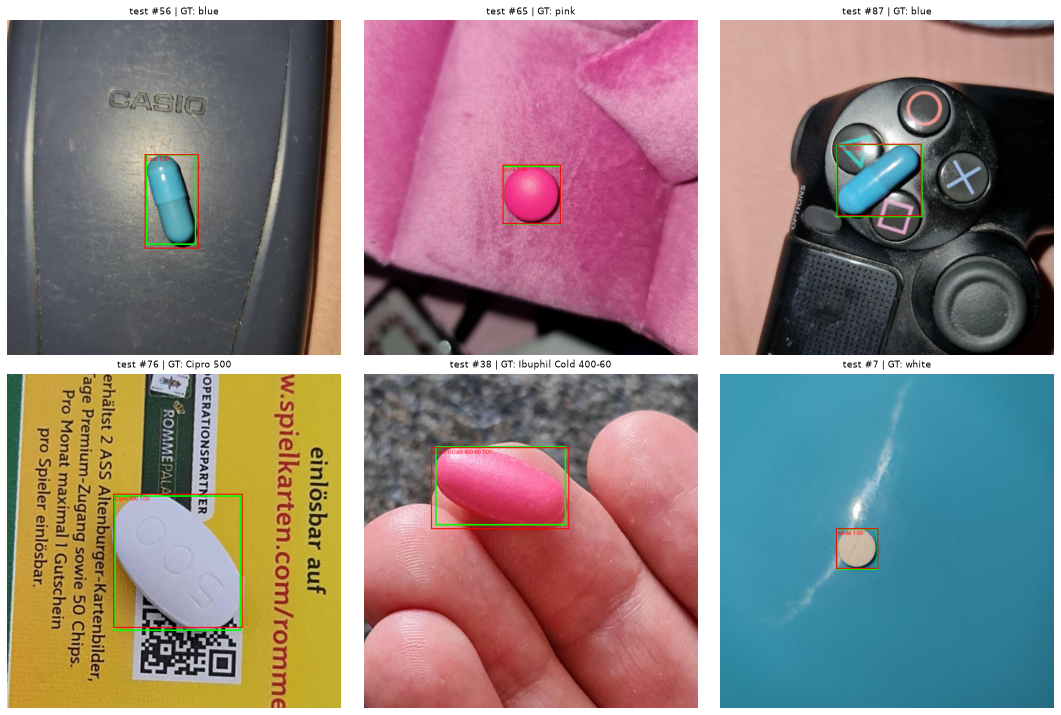

In [ ]:
C.plot_examples(model, ds["test"], CLASSES, OUT_DIR / "ejemplos_test.png", seed=SEED)

## 7. ¿Ha mejorado la localización? Análisis de errores

Se repite el análisis de errores de la sección 13 del baseline con el modelo de esta mejora, con las mismas figuras y en el mismo orden, para poder comparar cada una con la del baseline: descomposición TIDE (7.1), AP en función del umbral de IoU (7.2), matriz de confusión (7.3) e imágenes con más errores (7.4). Todas las figuras se muestran y se guardan en `resultados/mejora01_cosine_fasterrcnn/` con el mismo nombre que en el baseline.

También se guardan las predicciones de validación y test (`preds_valid.json`, `preds_test.json`): servirán para la comparativa final y para probar TTA o ensembles sin volver a ejecutar el modelo.

> **Nota sobre las salidas.** En la ejecución de Kaggle solo se calcularon la tabla TIDE (7.1) y las curvas de 7.2. Las celdas de las figuras se añadieron después, y sus salidas se obtuvieron ejecutando este mismo código sobre las predicciones guardadas de esta ejecución. El TIDE recalculado coincide exactamente con la tabla de 7.1.

### 7.1 Descomposición TIDE

Como en la sección 13.3 del baseline, a IoU 0.5 y 0.85. Si la hipótesis es correcta, **el ΔAP de `loc` a IoU 0.85 debe bajar** respecto al baseline (+0.096 en validación, +0.092 en test), mientras que el resto de errores no tiene por qué cambiar. La tabla compara los dos modelos; las barras muestran el ΔAP de cada tipo de error en esta mejora.

In [9]:
split_data = {
    "valid": C.collect_predictions(model, loaders["valid"], CLASSES),
    "test": C.collect_predictions(model, loaders["test"], CLASSES),
}
C.save_predictions(split_data, OUT_DIR)

tide = C.tide_analysis(split_data)
print()
C.compare_tide({"baseline": baseline["tide"], "mejora 1": C.tide_to_json(tide)})

partición@IoU   AP base |          loc |          cls |          dup |           bg |         miss
valid@0.5         1.000 |    0  +0.000 |    2  +0.000 |    0  +0.000 |    6  +0.000 |    0  +0.000
valid@0.85        0.970 |    3  +0.030 |    0  +0.000 |    0  +0.000 |    6  +0.000 |    0  +0.000
test@0.5          0.985 |    1  +0.000 |   10  +0.003 |    0  +0.000 |   13  +0.001 |    2  +0.011
test@0.85         0.922 |    8  +0.063 |    7  +0.000 |    0  +0.000 |   13  +0.002 |    2  +0.011


=== valid@0.85 ===
experimento                 AP base |           loc |           cls |           dup |            bg |          miss
baseline                      0.904 |    4   +0.096 |    4   +0.020 |    0   +0.000 |    9   +0.000 |    0   +0.000
mejora 1                      0.970 |    3   +0.030 |    0   +0.000 |    0   +0.000 |    6   +0.000 |    0   +0.000

=== test@0.85 ===
experimento                 AP base |           loc |           cls |           dup |            bg |          miss
b

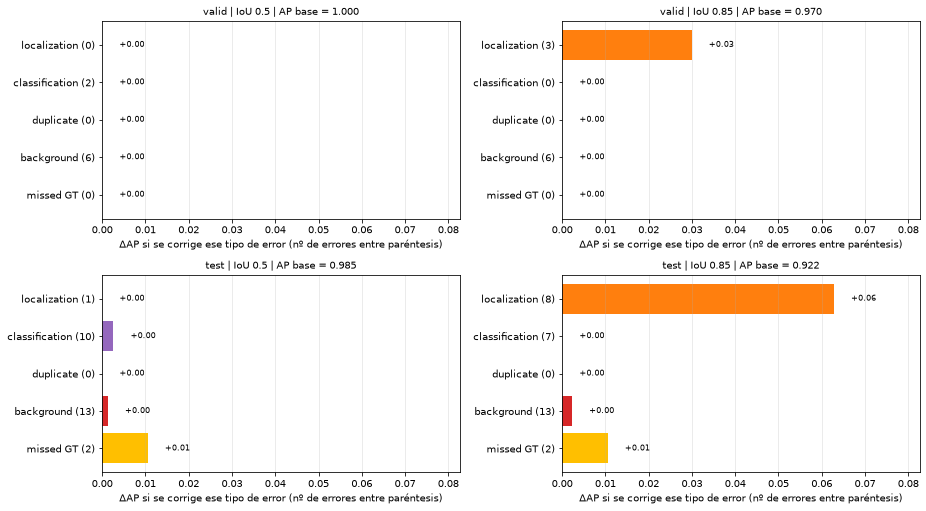

In [ ]:
C.plot_tide(tide, OUT_DIR / "tide.png")

### 7.2 AP en función del umbral de IoU

Como en la sección 13.2 del baseline: AP para cada umbral de IoU entre 0.05 y 0.95 (izquierda) e histograma del IoU de cada acierto con su caja real (derecha).

- En el baseline, la curva era plana hasta IoU ≈ 0.8 y caía en picado después: el modelo encontraba las pastillas pero no ajustaba la caja al píxel.
- Si la mejora actúa sobre la localización, la caída debe empezar **más tarde** y el histograma debe concentrarse **más cerca de 1**.

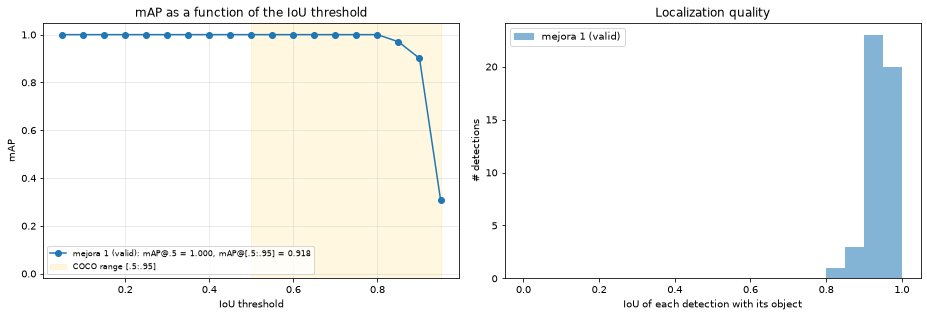

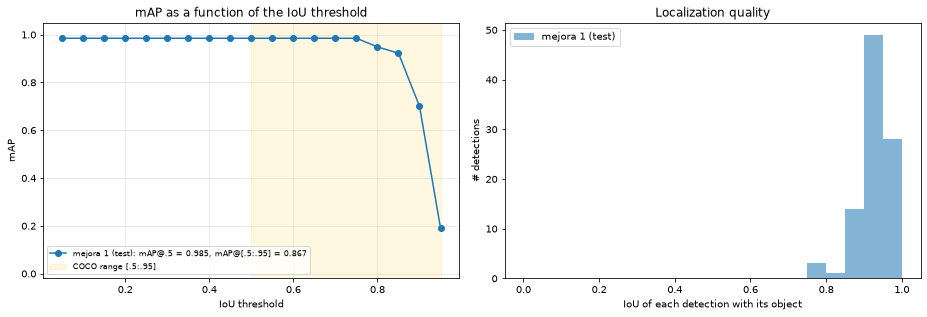

In [ ]:
C.plot_ap_vs_iou(split_data, "mejora 1", OUT_DIR)

### 7.3 Matriz de confusión

Como en la sección 13.4 del baseline, por imagen y con las detecciones de score ≥ 0.5: cada caja real se empareja con la detección de mayor score que la solape con IoU ≥ 0.5, sea de la clase que sea (si no hay ninguna, cuenta como *no detectado*). Las detecciones sin emparejar van a la fila *fondo* (falsos positivos). La diagonal son los aciertos.

Qué comparar con el baseline:
- **Confusiones entre pastillas blancas** (`Cipro 500`, `Xyzall 5mg`, `white`): en el baseline había 4 con score ≥ 0.5, una de ellas la doble anotación de la imagen 74 (`Cipro 500` → `Ibuphil Cold 400-60`), que no es un error del modelo.
- **Fila *fondo***: falsos positivos con score alto, como los lunares de la imagen 81.
- **Columna *no detectado***: en test son las 2 cajas mal anotadas de la imagen 74, que ningún modelo puede acertar.

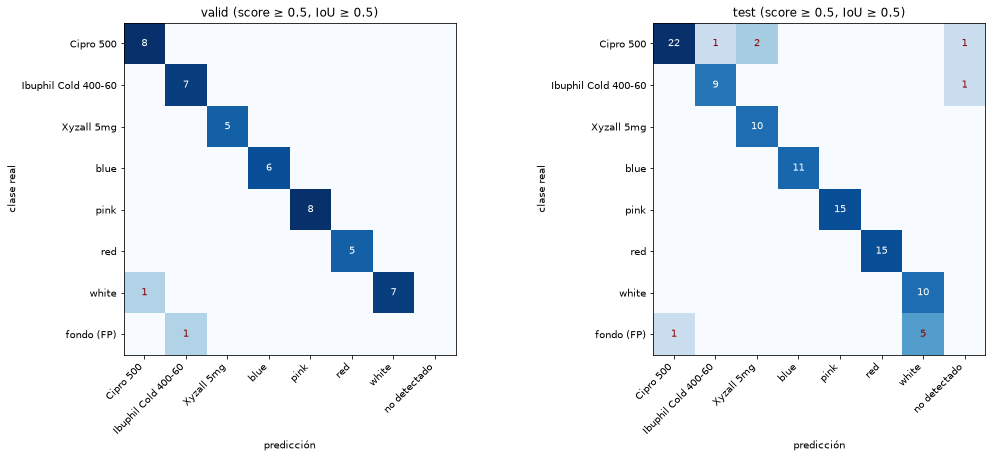

valid: 46 aciertos | 1 confusiones entre clases | 1 falsos positivos de fondo | 0 no detectadas
   confusión  white -> Cipro 500: 1
   fondo detectado como Ibuphil Cold 400-60: 1
test: 92 aciertos | 3 confusiones entre clases | 6 falsos positivos de fondo | 2 no detectadas
   confusión  Cipro 500 -> Ibuphil Cold 400-60: 1
   confusión  Cipro 500 -> Xyzall 5mg: 2
   fondo detectado como Cipro 500: 1
   fondo detectado como white: 5
   Cipro 500 no detectada: 1
   Ibuphil Cold 400-60 no detectada: 1


In [ ]:
cms = C.plot_confusion(split_data, CLASSES, OUT_DIR / "matriz_confusion.png")
C.print_confusion_summary(cms, CLASSES)

### 7.4 Imágenes con más errores

Como en la sección 13.5 del baseline: imágenes de test con más errores a IoU 0.5 y score ≥ 0.3. Blanco = caja real, ámbar discontinuo = no detectada, verde = acierto, y el resto de colores según el tipo de error (la etiqueta indica tipo, clase y score).

Qué mirar:
- **Imagen 74**: la pastilla rosa tiene dos cajas reales superpuestas (`Ibuphil Cold 400-60` y `Cipro 500`) y hay una caja `Cipro 500` de 0.5×2 píxeles. Son los 2 `miss` de test: errores de anotación, no del modelo.
- **Imagen 81**: los lunares azul claro del fondo detectados como pastillas `white`.

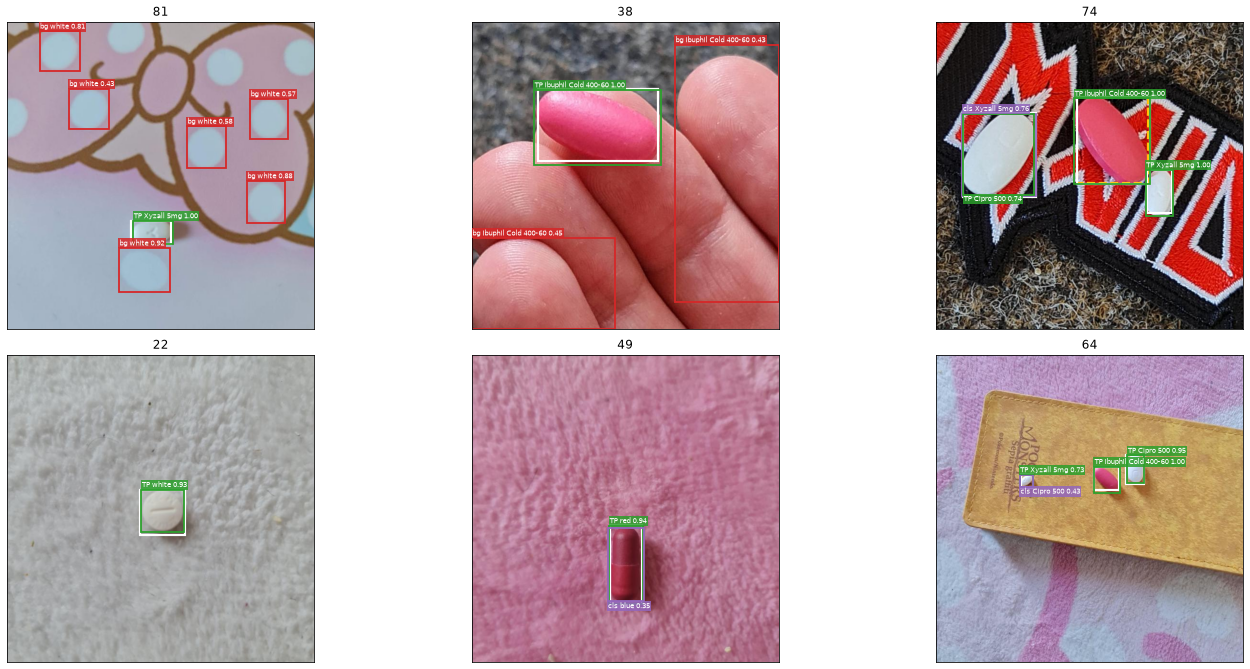

In [ ]:
gts_test, preds_test = split_data["test"]
C.plot_worst_images(gts_test, preds_test, tide["test@0.5"], ds["test"], OUT_DIR / "peores_imagenes_test.png")

## 8. Guardar resultados

`results.json`, `history.json`, `tide.json` y las predicciones quedan en `faster_rcnn/resultados/mejora01_cosine_fasterrcnn/`. Los `.json` se suben al repositorio para el cuaderno de comparativa; los pesos (`best_model.pth`) y las figuras no.

In [11]:
C.save_experiment(OUT_DIR, summary, tide)

# En Kaggle: comprimir la carpeta de resultados para descargarla
if Path("/kaggle/working").exists():
    import shutil
    from IPython.display import FileLink

    shutil.make_archive(f"/kaggle/working/{EXP_NAME}", "zip", OUT_DIR)
    display(FileLink(f"{EXP_NAME}.zip"))

Guardado en resultados/mejora01_cosine_fasterrcnn/


/kaggle/working/mejora01_cosine_fasterrcnn.zip

## 9. Conclusiones

### Resultados

| Métrica | Baseline | Mejora 1 | Diferencia |
|---|---|---|---|
| **val mAP@0.5:0.95** (decisión) | 0.881 | **0.918** | **+3.7** |
| test mAP@0.5:0.95 | 0.840 | **0.867** | **+2.7** |
| test mAP@0.5 | 0.981 | 0.985 | +0.4 |
| test mAP@0.75 | 0.975 | 0.985 | +1.0 |
| test mAR@100 | 0.864 | 0.889 | +2.4 |
| AP@0.85 (TIDE) val / test | 0.904 / 0.894 | 0.970 / 0.922 | +6.6 / +2.8 |
| ΔAP de `loc` a IoU 0.85, val / test | +0.096 / +0.092 | +0.030 / +0.063 | −0.066 / −0.029 |
| Inferencia (T4) | 175 ms | 174 ms | igual |
| Entrenamiento | 39 min | 78 min | ×2 |

**La mejora funciona y lo hace por el motivo previsto.**

1. **Sube el mAP en validación (+3.7) y en test (+2.7)**, y mejoran las **7 clases** en test (entre +1.3 y +4.2 puntos de AP).
2. **La ganancia está en la localización.** mAP@0.5 apenas cambia (+0.4) y casi toda la subida está en los umbrales de IoU altos. En TIDE, el ΔAP de `loc` a IoU 0.85 baja de 0.096 a 0.030 en validación y de 0.092 a 0.063 en test, y los errores de localización pasan de 12 a 8 en test. Es lo que predecía la hipótesis: con un LR que baja al final, el modelo hace los ajustes finos que necesita la regresión de cajas. En test, mAP@0.75 = mAP@0.5 = 0.985: toda pastilla bien detectada tiene ya IoU ≥ 0.75.
3. **El coste está solo en el entrenamiento**, que tarda el doble. El modelo es el mismo, así que la inferencia no cambia.

### Lo que no salió como se esperaba

- **El mAP de validación no se estabiliza.** Sigue oscilando al final aunque el LR sea casi cero: baja a 0.882 en la época 26 y otra vez en la 30, con LR = 1e-5. La desviación típica de las últimas 5 épocas (0.013) es incluso mayor que en el baseline (0.009). La causa no es el optimizador sino **el tamaño de la validación**: 45 imágenes y 47 pastillas, así que que una sola detección cambie de clase o de score mueve el mAP 1–3 puntos. En las épocas 26 y 30, el mAP@0.5 de validación cae de 1.000 a 0.974, que es exactamente una pastilla.
  - Consecuencia: elegir la mejor de 30 épocas con una métrica tan ruidosa es **optimista**. El 0.918 de validación está algo inflado, y la ganancia de test (+2.7), que es independiente, es la estimación más fiable.
- **No se sabe qué parte de la ganancia viene de entrenar más y qué parte de bajar el LR.** En la época 15 (el final del baseline), la mejora 1 estaba en 0.887 de validación, prácticamente igual que el baseline (0.881). Toda la ventaja aparece en la segunda mitad, cuando el LR baja. Para separar los dos efectos haría falta repetir el experimento con 15 épocas y coseno.
- **Los falsos positivos sobre el fondo de lunares (imagen 81 de test) empeoran.** Hay 5 detecciones `white` con score ≥ 0.5 (hasta 0.92), frente a 3 en el baseline (hasta 0.80). El modelo ha aprendido "círculo claro = pastilla blanca", y entrenar más lo refuerza. Apenas cuesta AP (`bg` +0.002 a IoU 0.85), pero con un umbral de confianza serían errores reales. Es un argumento a favor del aumento de datos (mejora 2).
- Es **una sola ejecución con una semilla**. Con estos tamaños de validación y test, diferencias de menos de 1 punto no serían concluyentes. +2.7 en test y una bajada clara de `loc` en las dos particiones sí lo son razonablemente.

### Corrección del análisis del baseline: las 2 pastillas "no detectadas" son errores de anotación

El análisis del baseline (13.6, punto 2) atribuía las 2 pastillas no detectadas de test (`miss`, +0.011) a pastillas pequeñas, por el mAP de objetos pequeños (0.35). Con la figura de imágenes con más errores de esta mejora (`peores_imagenes_test.png`, imagen 74) se ve que **son errores de anotación**:

- La pastilla rosa de la imagen 74 está anotada **dos veces sobre la misma caja**: como `Ibuphil Cold 400-60` (correcta, el modelo la acierta con score 1.00) y como `Cipro 500`.
- Hay una caja `Cipro 500` de **0.5 × 2 píxeles** en la misma imagen.

Ningún modelo puede acertarlas, por eso `miss` es idéntico en el baseline y en la mejora 1. Consecuencias:

- El **mAP@0.5 máximo alcanzable en test es menor que 1**, y el AP50 de `Cipro 500` (0.919) está limitado por estas dos cajas, no solo por confusiones del modelo.
- El **mAP de objetos pequeños de test no es interpretable**: solo hay 2 objetos pequeños y uno es la caja degenerada. Por eso baja de 0.35 a 0.30 sin que el modelo haya empeorado.
- Las mejoras pensadas para el recall de pastillas pequeñas (anclas más pequeñas, más resolución) **pierden su justificación**.
- En la matriz de confusión de test, la confusión `Cipro 500 → Ibuphil Cold 400-60` es esa doble anotación. Las confusiones reales con score ≥ 0.5 son 2 (`Cipro 500 → Xyzall 5mg`, imágenes 47 y 74), frente a 3 en el baseline (4 contando también la doble anotación).

### Decisión

**Se adopta esta política de entrenamiento** (30 épocas, *warmup* + coseno) como receta para las siguientes mejoras: `USE_MEJORA1_RECIPE = True` en la mejora 2, cuyo efecto se medirá frente a esta.

Margen que queda, por orden: (1) la localización sigue siendo el error más costoso a IoU 0.85 (+0.063 en test); (2) los falsos positivos sobre fondos con círculos claros; (3) las confusiones `Cipro 500 ↔ Xyzall 5mg` entre pastillas blancas. `miss` no es mejorable.